In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

This notebook simulates Brownian Motion, the stock price in the Black-Scholes Model (Geometric Brownian Motion) and computes prices and replicating portfolios for European call and put options.

## Simulating Brownian Motion

Below we define a function that simulates Bronwian motion. Given a time horizon $T > 0$ we split the interval $[0,T]$ into the partition of size $M+1$, $\mathbb{T}_M = \{0,dt,2dt,\dots,Mdt\}$ where $dt = T/M$ is a small number. We then write the telescoping sum

$$W_T = \sum_{t \in \mathbb{T}_M^*} (W_t-W_{t-dt}),$$

where $\mathbb{T}_M^* = \mathbb{T}_M\setminus\{0\}$. Since the increment $W_t-W_{t-dt} \sim N(0,dt)$ is independent of the remaining increments we can simulate Brownian motion by simply simulating these increments independently. 

This is how the function below works.

In [2]:
def sim_BM(T,M,N):
    '''
    inputs: 
    T -> Time horizon of interest
    M -> Number of partition points
    N -> Number of Brownian paths to simulate 
    
    outputs:
    W -> numpy array of size N x M, where each row is a Brownian path
    '''
    
    dt = T/M # step size
    # simulate independent normal random variables with mean 0 and variance dt stored in an M x N array
    dW = np.sqrt(dt)*np.random.normal(0,1,(N,M)) 
    W = np.cumsum(dW,axis=1) # compute W
    W = np.append(np.zeros((N,1)),W,axis=1) # add in initial value zero
    
    return W

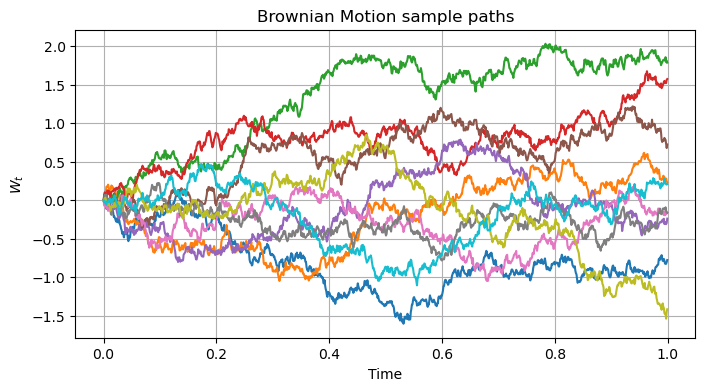

In [3]:
# plot paths of Brownian Motion

# parameters
T = 1 # time horizon
M = 1000 # number of timesteps
N = 10 # number of paths to simulate

# simulate BM
W = sim_BM(T,M,N)

# define time grid
t = np.arange(0,T,T/(M+1))

# plotting
plt.subplots(figsize=(8,4))

for i in range(N):
    plt.plot(t,W[i,:])
    
plt.xlabel('Time')
plt.ylabel(r'$W_t$')
plt.title('Brownian Motion sample paths')

plt.grid('True')
plt.show()

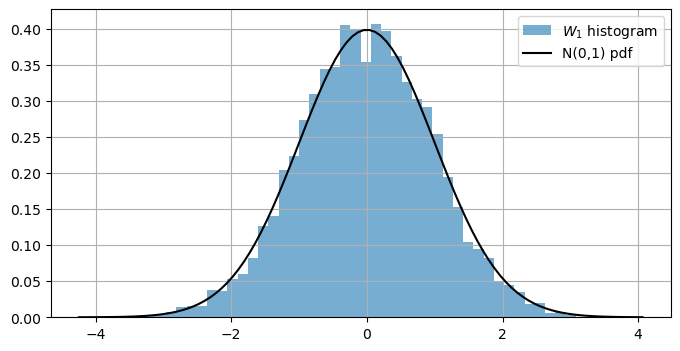

In [4]:
# Brownian motion histograms at time T overlayed with Normal pdf

# parameters
T = 1
M = 1000
N = 10000

# simulate BM
W = sim_BM(T,M,N)

# plot histogram
plt.subplots(figsize=(8,4))
plt.hist(W[:,-1],bins=50,density=True,alpha=0.6, label = r'$W_1$ histogram') # histogrram of W

# overlay Gaussian density
xmin, xmax = plt.xlim() # get the right range
x = np.linspace(xmin, xmax, 100)
plt.plot(x,norm.pdf(x), 'k',label = 'N(0,1) pdf') # compute and plot the pdf
plt.legend()
plt.grid(True)
plt.show()

## Simulating the stock price 

Here we simulate $S_t = S_0\exp((r-\frac{1}{2}\sigma^2)t + \sigma W_t^{\mathbb{Q}})$

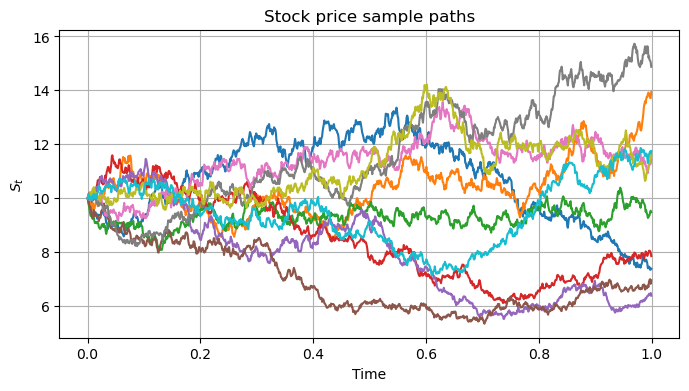

In [5]:
# parameters
r = 0.03 # interest rate
sigma = 0.3 # volatility
S0 = 10 # initial price
T = 1 # time horizons
M = 1000 # number of time steps
N = 10 # number of sample paths

# simulate Brownian motion
W = sim_BM(T,M,N)

# define time grid
t = np.arange(0,T,T/(M+1))

# compute stock price
S = S0*np.exp((r-1/2*sigma**2)*t+sigma*W)

# plotting
plt.subplots(figsize=(8,4))

for i in range(N):
    plt.plot(t,S[i,:])
    
plt.xlabel('Time')
plt.ylabel(r'$S_t$')
plt.title('Stock price sample paths')

plt.grid('True')
plt.show()

## Call prices

Here we use the Black-Scholes formula to compute call prices $C_t$ and the replicating portfolio $\theta_t$ at different times and plot the corresponding values as a function of the current stock price

In [6]:
# define call price function

def BS_call_price(x,K,r,sigma,tau):
    '''
    inputs:
    x -> current price (L dimensional vector)
    K -> strike price
    r -> interest rate
    sigma -> volatility
    tau -> time until expiry (M dimensional vector)

    returns:
    prices -> (M x L) dimensional array with the (t,x) element denoting the price if S_t = x at time t.
    '''
    L = len(x)
    M = len(tau)
    prices = np.zeros((M,L)) # initialize prices
    for i in range(M): # for each time
        time = tau[i] 
        if time ==0: # at expiry return call payoff:
            prices[i,:] = np.maximum(x-K,0)
            continue
        else: # use Black-Scholes formula:
            d_minus = (np.log(x/K) + (r-1/2*sigma**2)*time)/(sigma*np.sqrt(time))
            d_plus = d_minus + sigma*np.sqrt(time)
            prices[i,:] = x*norm.cdf(d_plus) - K*np.exp(-r*time)*norm.cdf(d_minus)
    return prices

# define hedge function

def BS_call_Delta(x,K,r,sigma,tau):
    '''
    inputs:
    x -> current price (L dimensional vector)
    K -> strike price
    r -> interest rate
    sigma -> volatility
    tau -> time until expiry (M dimensional vector)

    returns:
    positions -> (M x L) dimensional array with the (t,x) element denoting the replicating strategy if S_t = x at time t.
    '''
    
    L = len(x)
    M = len(tau)
    positions = np.zeros((M,L)) # initialize position
    for i in range(M): # for each time
        time = tau[i] 
        if time ==0: # at expiry return indicator function payoff:
            positions[i,:] = np.sign(np.maximum(x-K,0))
            continue
        else: # use Black-Scholes Delta formula for dc/dx:
            d_plus = (np.log(x/K) + (r+1/2*sigma**2)*time)/(sigma*np.sqrt(time))
            positions[i,:] = norm.cdf(d_plus)
    return positions

In [7]:
# parameters
r = 0.03 # interest rate
sigma = 0.3 # volatility
S0 = 10 # initial price
K = S0 # strike price
T = 1 # time horizons
M = 100 # number of time steps
L = 100 # number of stock-price grid points

# define time grid 
t = np.linspace(0,T,M+1)
dt = t[1]-t[0]

# define price grid of interest
x = np.linspace(K*0.6,K*1.4,L) # around the strike

# compute call prices at each t and x
call_prices = BS_call_price(x,K,r,sigma,T-t)

# compute replicating strategy at each t and x
replicating_positions_call = BS_call_Delta(x,K,r,sigma,T-t)

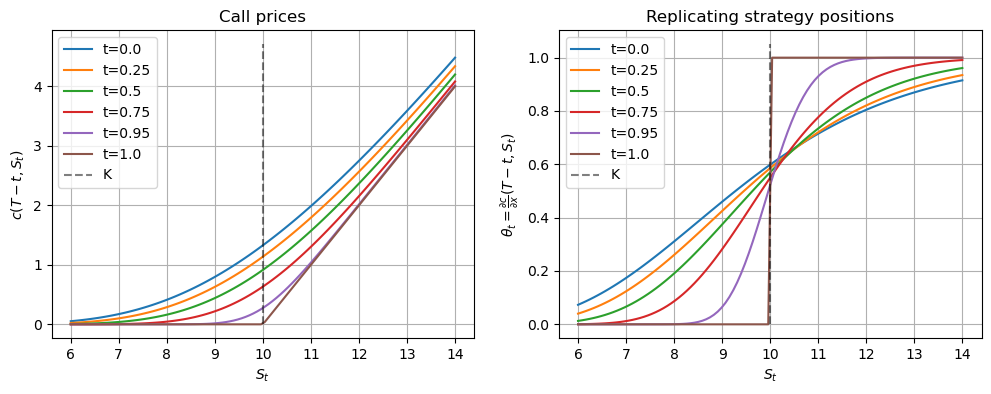

In [33]:
# plotting

## pick times to plots price curve

# times_to_plot = np.array([0,T/2,T]) 
times_to_plot = np.array([0,T/4,T/2,3*T/4,95*T/100,T]) 
time_indices = np.array([np.argmin(np.abs(t - time)) for time in times_to_plot]) find corresponding time indices

## plotting
fig, ax = plt.subplots(1,2,figsize=(12,4))

# plot prices and hedges
for i in time_indices:
    ax[0].plot(x,call_prices[i,:], label = 't={}'.format(np.round(t[i],2)))
    ax[1].plot(x,replicating_positions_call[i,:],label='t={}'.format(np.round(t[i],2)))

# plot vertical dashed line at K
ax[0].vlines(K,0,ax[0].get_ylim()[1],linestyle = '--', label = 'K', color='k', alpha = 0.5)  
ax[1].vlines(K,0,ax[1].get_ylim()[1],linestyle = '--', label = 'K', color='k', alpha = 0.5)  

# legend and grid
ax[0].legend()
ax[0].grid()

ax[1].legend()
ax[1].grid()

# title and axis labels
ax[0].set_xlabel('$S_t$')
ax[0].set_ylabel('$c(T-t,S_t)$')

ax[1].set_xlabel('$S_t$')
ax[1].set_ylabel(r'$\theta_t = \frac{\partial c}{\partial x}(T-t,S_t)$')

ax[0].set_title('Call prices')
ax[1].set_title('Replicating strategy positions')
plt.show()

## Put prices

 Analogous analysis for put options

In [9]:
# define call price function

def BS_put_price(x,K,r,sigma,tau):
    '''
    inputs:
    x -> current price (L dimensional vector)
    K -> strike price
    r -> interest rate
    sigma -> volatility
    tau -> time until expiry (M dimensional vector)

    returns:
    prices -> (M x L) dimensional array with the (t,x) element denoting the price if S_t = x at time t.
    '''
    L = len(x)
    M = len(tau)
    prices = np.zeros((M,L)) # initialize prices
    for i in range(M): # for each time
        time = tau[i] 
        if time ==0: # at expiry return put payoff:
            prices[i,:] = np.maximum(K-x,0)
            continue
        else: # use Black-Scholes formula:
            d_minus = (np.log(x/K) + (r-1/2*sigma**2)*time)/(sigma*np.sqrt(time))
            d_plus = d_minus + sigma*np.sqrt(time)
            prices[i,:] = K*np.exp(-r*time)*norm.cdf(-d_minus) - x*norm.cdf(-d_plus)
    return prices

def BS_put_Delta(x,K,r,sigma,tau):
    '''
    inputs:
    x -> current price (L dimensional vector)
    K -> strike price
    r -> interest rate
    sigma -> volatility
    tau -> time until expiry (M dimensional vector)

    returns:
    positions -> (M x L) dimensional array with the (t,x) element denoting the replicating strategy if S_t = x at time t.
    '''
    
    L = len(x)
    M = len(tau)
    positions = np.zeros((M,L)) # initialize position
    for i in range(M): # for each time
        time = tau[i] 
        if time ==0: # at expiry return indicator function payoff:
            positions[i,:] = -np.sign(np.maximum(K-x,0))
            continue
        else: # use Black-Scholes Delta formula for dc/dx:
            d_plus = (np.log(x/K) + (r+1/2*sigma**2)*time)/(sigma*np.sqrt(time))
            positions[i,:] = -norm.cdf(-d_plus)
    return positions

In [10]:
# parameters
r = 0.03 # interest rate
sigma = 0.3 # volatility
S0 = 10 # initial price
K = S0 # strike price
T = 1 # time horizons
M = 100 # number of time steps
L = 100 # number of stock-price grid points

# define time grid 
t = np.linspace(0,T,M+1)

# define price grid of interest
x = np.linspace(K*0.6,K*1.4,L) # around the strike

# compute call prices at each t and x
put_prices = BS_put_price(x,K,r,sigma,T-t)

# compute replicating strategy at each t and x
replicating_positions_put = BS_put_Delta(x,K,r,sigma,T-t)

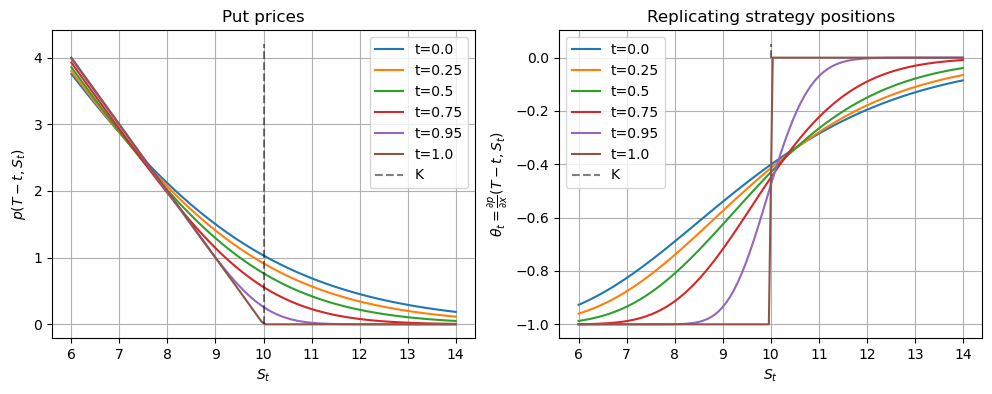

In [42]:
# plotting

## pick times to plots price curve

# times_to_plot = np.array([0,T/2,T]) 
times_to_plot = np.array([0,T/4,T/2,3*T/4,95*T/100,T]) 
time_indices = np.array([np.argmin(np.abs(t - time)) for time in times_to_plot]) # find corresponding time indices

## plotting
fig, ax = plt.subplots(1,2,figsize=(12,4))

# plot prices and hedges
for i in time_indices:
    ax[0].plot(x,put_prices[i,:], label = 't={}'.format(np.round(t[i],2)))
    ax[1].plot(x,replicating_positions_put[i,:],label='t={}'.format(np.round(t[i],2)))

# plot vertical dashed line at K
ax[0].vlines(K,0,ax[0].get_ylim()[1],linestyle = '--', label = 'K', color='k', alpha = 0.5)  
ax[1].vlines(K,0,ax[1].get_ylim()[1],linestyle = '--', label = 'K', color='k', alpha = 0.5)  

# legend and grid
ax[0].legend()
ax[0].grid()

ax[1].legend()
ax[1].grid()

# title and axis labels
ax[0].set_xlabel('$S_t$')
ax[0].set_ylabel('$p(T-t,S_t)$')

ax[1].set_xlabel('$S_t$')
ax[1].set_ylabel(r'$\theta_t = \frac{\partial p}{\partial x}(T-t,S_t)$')

ax[0].set_title('Put prices')
ax[1].set_title('Replicating strategy positions')
plt.show()